### Step 1: Importing Libraries

In [32]:
#!pip install -q geemap
#!pip install -q rasterio
#!pip install -q pulp
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import torchvision
from sklearn.model_selection import train_test_split
from PIL import Image
from tensorflow.keras import layers
from google.colab import drive
import os
import ee, geemap
import rasterio
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.warp import transform as warp_transform
from PIL import Image
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
import requests
from scipy.spatial import cKDTree
import geopandas as gpd
import pulp
import zipfile, glob, os
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

### Step 2: Changing the runtime type to T4 GPU

In [33]:
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Step 3: Loading EuroSAT to Train the CNN

### Step 3.1: Download EuroSAT RGB (27,000 Sentinel-2 tiles, 64x64, 10 classes)

In [34]:
root = '/content/data'
torchvision.datasets.EuroSAT(root=root, download=True)
data_dir = pathlib.Path(root) / 'eurosat' / '2750'

100%|██████████| 94.3M/94.3M [00:00<00:00, 106MB/s]


### Step 3.2: List every image file and its class (folder name = class)

In [35]:
class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())
paths, labels = [], []
for i, c in enumerate(class_names):
    for f in sorted((data_dir / c).glob('*.jpg')):
        paths.append(str(f))
        labels.append(i)
paths, labels = np.array(paths), np.array(labels)

print("\nClasses:", class_names)


Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


### Step 3.3: Stratified split: 70% train, 15% validation, 15% test

In [36]:
p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

print("Total:", len(paths), "| Train:", len(p_train),
      "| Val:", len(p_val), "| Test:", len(p_test))

print("\nTraining images per class:")
for name, c in zip(class_names, np.bincount(y_train)):
    print(f"  {name:22s} {c}")

Total: 27000 | Train: 18900 | Val: 4050 | Test: 4050

Training images per class:
  AnnualCrop             2100
  Forest                 2100
  HerbaceousVegetation   2100
  Highway                1750
  Industrial             1750
  Pasture                1400
  PermanentCrop          1750
  Residential            2100
  River                  1750
  SeaLake                2100


### Step 3.4: Showing one example per class

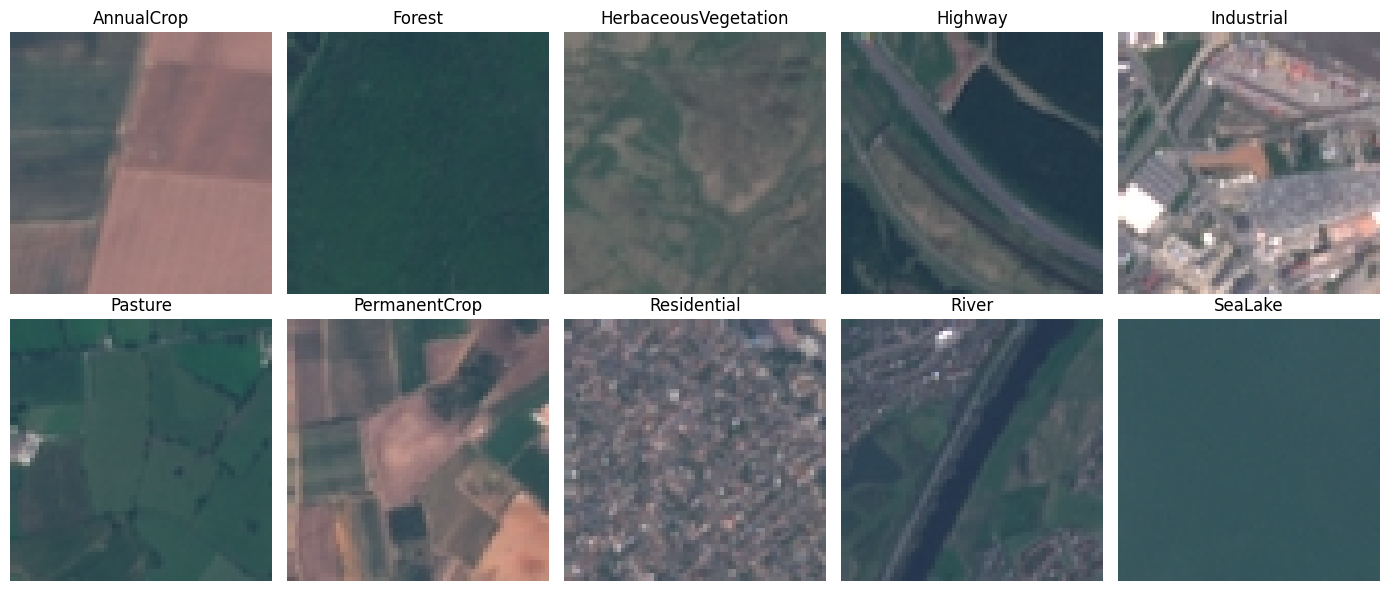

In [37]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_train == i)[0][0]
    ax.imshow(Image.open(p_train[idx]))
    ax.set_title(class_names[i])
    ax.axis('off')
plt.tight_layout()
plt.show()

### STEP 4: Build and train the CNN (transfer learning)

### Step 4.1: Connect Google Drive so the trained model is saved permanently.

In [38]:
#    (Colab deletes everything in /content when the session ends.)
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/mwanza_project'
os.makedirs(SAVE_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Step 4.2: Basic settings.

In [39]:
#    IMG   = size each image is resized to (128 x 128 pixels)
#    BATCH = how many images the model looks at before updating itself once
#    Fixing the random seed makes results repeatable every time we rerun.

IMG, BATCH = 128, 64
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(42)

### Step 4.3: Function to open ONE image from disk and prepare it.

In [40]:
#    It reads the JPG file, turns it into numbers (pixels),
#    and enlarges it from 64x64 to 128x128, because EfficientNet
#    was originally trained on bigger images and sees detail better that way.

def load(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return img, label

### Step 4.4: Function to build a data "conveyor belt" that feeds images to the model.

In [41]:
#    - For training only, it shuffles the images so the model doesn't
#      see all the Forest pictures, then all the River pictures, in order.
#    - It groups images into batches and prepares the next batch
#      while the GPU is busy (prefetch), so training runs faster.

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=42)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

### Step 4.5: Build the three conveyor belts from the split we made in Step 1.

In [42]:
train_ds = make_ds(p_train, y_train, training=True)   # to learn from
val_ds   = make_ds(p_val, y_val)                       # to check progress each epoch
test_ds  = make_ds(p_test, y_test)                     # final exam, used only at the end

### Step 4.6: Data augmentation

In [43]:
#     Showing the model slightly changed copies of each image
#     during training, so it learns the TRUE pattern and not small accidents.

#     Random contrast and brightness:
#      - EuroSAT images are from Europe; our real images are from Mwanza,
#        where sunlight, soil colour and haze are different.
#        Changing contrast/brightness teaches the model to recognise shapes
#        and textures instead of relying on exact European colours.

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.1),
], name="augmentation")

### Step 4.7: Load EfficientNetB0 that is ALREADY trained on 1.2 million everyday photos.

In [44]:
#    include_top=False -> remove its old final layer (which chose among cats,
#    cars, etc.) because we need our own 10 land-use classes instead.
#    trainable=False -> freeze it for now so its knowledge is not changed.

base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights='imagenet', input_shape=(IMG, IMG, 3))
base.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Step 4.8: Assemble the full model, layer by layer.

In [45]:
inputs = tf.keras.Input(shape=(IMG, IMG, 3))
x = augment(inputs)
x = base(x, training=False)          # keeps EfficientNet's internal statistics fixed
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

### Step 4.9: PHASE A: train ONLY the new final layer (EfficientNet stays frozen).

In [46]:
#    Learning rate 1e-3 (0.001) is normal speed because the new layer
#    starts from nothing and needs to learn quickly.

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("\n=== Phase A: frozen base ===")
hist_a = model.fit(train_ds, validation_data=val_ds, epochs=5)


=== Phase A: frozen base ===
Epoch 1/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 75s 156ms/step - accuracy: 0.8156 - loss: 0.6352 - val_accuracy: 0.9044 - val_loss: 0.3278
Epoch 2/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 27s 33ms/step - accuracy: 0.9033 - loss: 0.3073 - val_accuracy: 0.9160 - val_loss: 0.2597
Epoch 3/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9150 - loss: 0.2610 - val_accuracy: 0.9237 - val_loss: 0.2292
Epoch 4/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9243 - loss: 0.2306 - val_accuracy: 0.9267 - val_loss: 0.2123
Epoch 5/5
296/296 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.9263 - loss: 0.2225 - val_accuracy: 0.9316 - val_loss: 0.2005


### Step 4.10: PHASE B: fine-tuning.

In [47]:
#     Unfreeze only the LAST 40 layers of EfficientNet (the ones that recognise
#     complex textures) so they can specialise in satellite images.
#     The early layers (basic edges and colours) stay frozen; they are
#     already useful for any image.

base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), # Use a very small learning rate (1e-5, 100x smaller than Phase A)
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, # EarlyStopping watches the validation loss: if it stops improving for 3 epochs in a row, training stops and the best version is kept.
                                         restore_best_weights=True)
print("\n=== Phase B: fine-tuning ===")
hist_b = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=[early])


=== Phase B: fine-tuning ===
Epoch 1/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 72s 139ms/step - accuracy: 0.8425 - loss: 0.4920 - val_accuracy: 0.9059 - val_loss: 0.2849
Epoch 2/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.8809 - loss: 0.3619 - val_accuracy: 0.9151 - val_loss: 0.2571
Epoch 3/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.8992 - loss: 0.3066 - val_accuracy: 0.9207 - val_loss: 0.2328
Epoch 4/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.9067 - loss: 0.2811 - val_accuracy: 0.9279 - val_loss: 0.2169
Epoch 5/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9163 - loss: 0.2561 - val_accuracy: 0.9328 - val_loss: 0.2043
Epoch 6/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.9213 - loss: 0.2391 - val_accuracy: 0.9365 - val_loss: 0.1946
Epoch 7/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 0.9246 - loss: 0.2294 - val_accuracy: 0.9390 - val_loss: 0.1866
Epoch 8/8
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0

### Step 4.12: Save the trained model to Google Drive.

In [48]:
#     We can reuse it on Mwanza images without retraining.

model.save(f'{SAVE_DIR}/eurosat_effnetb0.keras')
print("\nModel saved to", SAVE_DIR)


Model saved to /content/drive/MyDrive/mwanza_project


### Step 4.13: Plot the learning curves (Phase A and Phase B joined together).

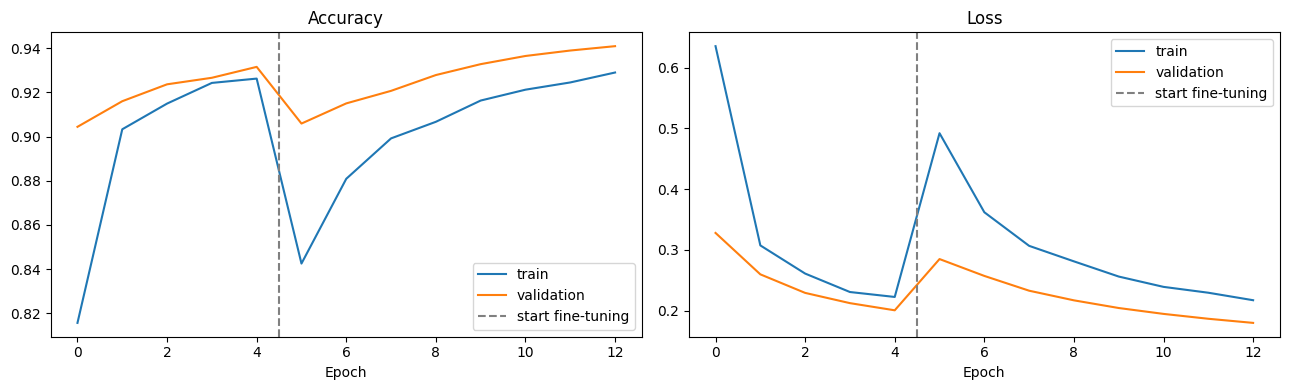

In [49]:
#     The grey dashed line marks where fine-tuning started.
#     Good sign: train and validation lines stay close together.
#     Warning sign: train keeps improving while validation gets worse (overfitting).

acc   = hist_a.history['accuracy'] + hist_b.history['accuracy']
vacc  = hist_a.history['val_accuracy'] + hist_b.history['val_accuracy']
loss  = hist_a.history['loss'] + hist_b.history['loss']
vloss = hist_a.history['val_loss'] + hist_b.history['val_loss']
split = len(hist_a.history['accuracy'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(acc, label='train'); ax[0].plot(vacc, label='validation')
ax[1].plot(loss, label='train'); ax[1].plot(vloss, label='validation')
for a, t in zip(ax, ['Accuracy', 'Loss']):
    a.axvline(split - 0.5, color='grey', ls='--', label='start fine-tuning')
    a.set_title(t); a.set_xlabel('Epoch'); a.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/training_curves.png', dpi=150)   # saved for the report
plt.show()

### Step 4.14: Continue fine-tuning (validation was still improving)

In [50]:
#    Continue training the SAME model from where Phase B stopped.
#    EarlyStopping will stop early if validation loss stops improving.

hist_c = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early])

Epoch 1/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9280 - loss: 0.2121 - val_accuracy: 0.9412 - val_loss: 0.1748
Epoch 2/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9330 - loss: 0.2043 - val_accuracy: 0.9427 - val_loss: 0.1698
Epoch 3/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.9361 - loss: 0.1891 - val_accuracy: 0.9442 - val_loss: 0.1668
Epoch 4/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.9399 - loss: 0.1820 - val_accuracy: 0.9447 - val_loss: 0.1626
Epoch 5/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9404 - loss: 0.1815 - val_accuracy: 0.9454 - val_loss: 0.1588
Epoch 6/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9420 - loss: 0.1746 - val_accuracy: 0.9449 - val_loss: 0.1563
Epoch 7/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9461 - loss: 0.1642 - val_accuracy: 0.9469 - val_loss: 0.1537
Epoch 8/10
296/296 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9461 - loss: 0.1588 - 

### Step 4.15: Save the improved model (replaces the old file on Drive).

In [51]:
model.save(f'{SAVE_DIR}/eurosat_effnetb0.keras')
print("\nModel saved.")


Model saved.


### Step 4.16: Redraw the full curves: Phase A + Phase B + continuation.

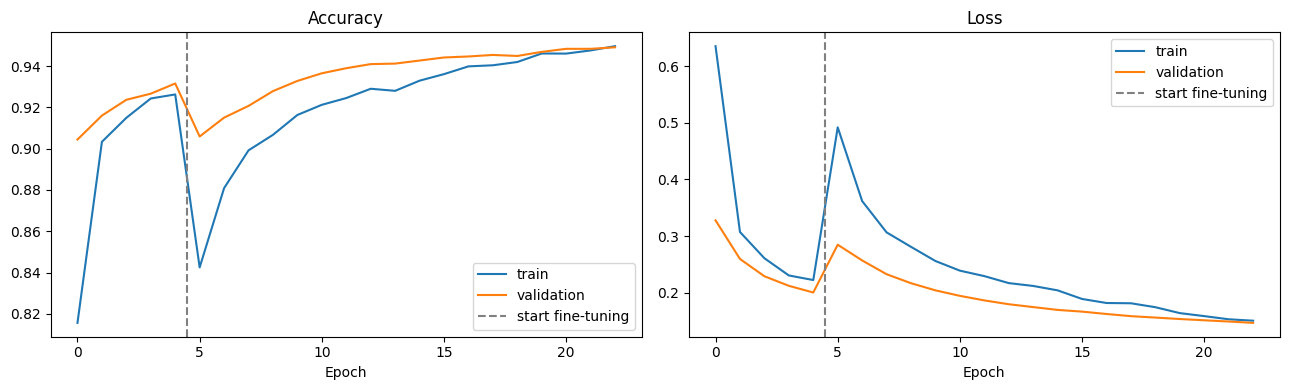

Best validation accuracy: 0.9491


In [52]:
acc   += hist_c.history['accuracy'];  vacc  += hist_c.history['val_accuracy']
loss  += hist_c.history['loss'];      vloss += hist_c.history['val_loss']

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(acc, label='train'); ax[0].plot(vacc, label='validation')
ax[1].plot(loss, label='train'); ax[1].plot(vloss, label='validation')
for a, t in zip(ax, ['Accuracy', 'Loss']):
    a.axvline(split - 0.5, color='grey', ls='--', label='start fine-tuning')
    a.set_title(t); a.set_xlabel('Epoch'); a.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/training_curves.png', dpi=150)
plt.show()
print(f"Best validation accuracy: {max(vacc):.4f}")

### Step 4.17: Evaluate on the test set.

### Step 4.17a: Ask the model to predict every test image.

In [53]:
probs  = model.predict(test_ds)
y_pred = probs.argmax(axis=1)

64/64 ━━━━━━━━━━━━━━━━━━━━ 16s 142ms/step


### Step 4.17b: Overall test accuracy

In [54]:
test_acc = (y_pred == y_test).mean()
print(f"TEST ACCURACY: {test_acc:.4f}\n")

TEST ACCURACY: 0.9588



### Step 4.17c: Per-class report

In [55]:
#    precision = when the model says "Residential", how often it is right
#    recall    = of all real Residential tiles, how many the model found
#    f1-score  = a single balance of precision and recall

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

                      precision    recall  f1-score   support

          AnnualCrop      0.936     0.938     0.937       450
              Forest      0.965     0.989     0.977       450
HerbaceousVegetation      0.952     0.960     0.956       450
             Highway      0.940     0.920     0.930       375
          Industrial      0.987     0.979     0.983       375
             Pasture      0.923     0.923     0.923       300
       PermanentCrop      0.953     0.920     0.936       375
         Residential      0.976     0.998     0.987       450
               River      0.957     0.952     0.955       375
             SeaLake      0.987     0.987     0.987       450

            accuracy                          0.959      4050
           macro avg      0.958     0.957     0.957      4050
        weighted avg      0.959     0.959     0.959      4050



### Step 4.17d: Confusion matrix

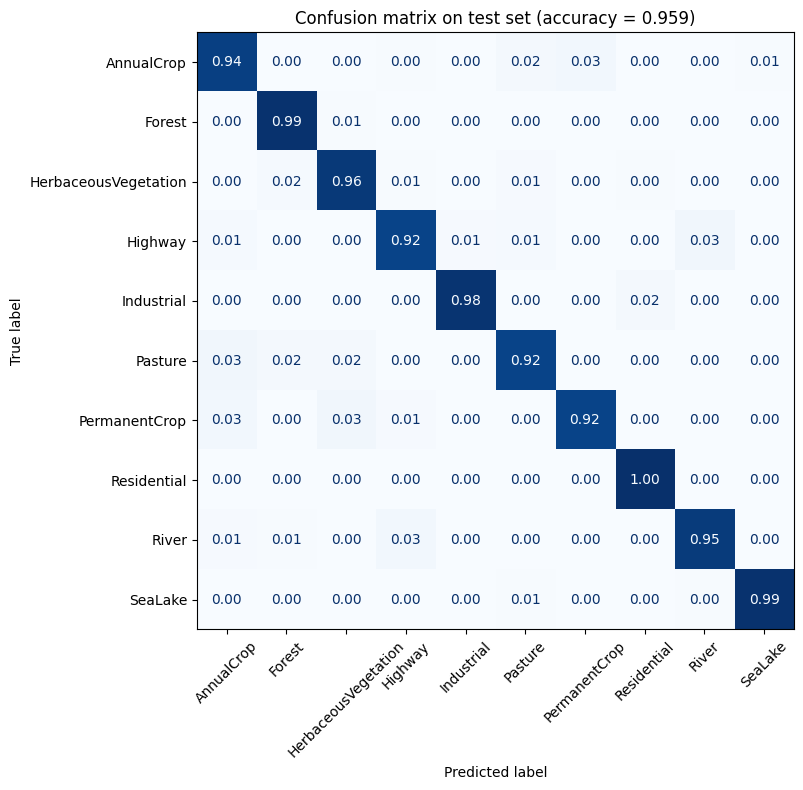

In [56]:
cm = confusion_matrix(y_test, y_pred, normalize='true')
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap='Blues', values_format='.2f', xticks_rotation=45, colorbar=False)
ax.set_title(f'Confusion matrix on test set (accuracy = {test_acc:.3f})')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/confusion_matrix.png', dpi=150)   # for the report
plt.show()

### Step 4.17e: Focus on Residential, our "where people live" signal.

In [57]:
r = class_names.index('Residential')
print("\nWhen a Residential tile is misclassified, it is mistaken for:")
for j in np.argsort(cm[r])[::-1]:
    if j != r and cm[r, j] > 0:
        print(f"  {class_names[j]:22s} {cm[r, j]*100:.1f}%")


When a Residential tile is misclassified, it is mistaken for:
  Industrial             0.2%


### Step 5: Connect Earth Engine and build a cloud-free Mwanza image

### Step 5.1: Log in to Earth Engine with registered project.

In [58]:
ee.Authenticate(auth_mode='notebook', force=True)
ee.Initialize(project='lab-5-healthcare')
print("Earth Engine connected ✔")

To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=4Y7MKWPS8fjKcs1Pml9uEqO_RTe1YRaBOs6PZ1vX488&tc=i3vUrihk-ByIgSFWphUXPx5WJBZRIN_HKM6cIxQBSz0&cc=1zce6gwO4LzxrES4qxVGAGx3KqrB57F2Y4ZBfW5gpXY

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AXlqoi4bjqWs4oQCLm3e30_Qm5hN46BlIsbfovJqMy0LGY2V_qxLdKBg_8E

Successfully saved authorization token.
Earth Engine connected ✔


### Step 5.2: Study area: a rectangle around Mwanza city (longitude/latitude corners).

In [59]:
#    West 32.70, South -2.85, East 33.20, North -2.35  (about 55 km x 55 km)

AOI = ee.Geometry.Rectangle([32.70, -2.85, 33.20, -2.35])

### Step 5.3: Choose the images.

In [60]:
#    S2_HARMONIZED = Sentinel-2 "Level-1C", the SAME processing level EuroSAT was
#    built from, so Mwanza images look as similar as possible to the training images.
#    June-September 2025 = dry season, the fewest clouds over Mwanza.

s2 = (ee.ImageCollection('COPERNICUS/S2_HARMONIZED')
        .filterBounds(AOI)
        .filterDate('2025-06-01', '2025-09-30'))

### Step 5.4: Remove clouds using Google's Cloud Score+.

In [61]:
#    Each pixel gets a "clearness" score from 0 (cloud) to 1 (clear sky);
#    we keep only pixels scoring 0.60 or higher.

csp = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
def mask_clouds(img):
    return img.updateMask(img.select('cs_cdf').gte(0.60))

### Step 5.5: Combine all clear pixels into ONE image using the median

In [62]:
#    (the middle value), which also removes leftover haze and shadows.

composite = (s2.linkCollection(csp, ['cs_cdf'])
               .map(mask_clouds)
               .median()
               .clip(AOI))
print("Number of Sentinel-2 images combined:", s2.size().getInfo())

Number of Sentinel-2 images combined: 254


### Step 5.6: Show it on an interactive map.

In [63]:
#    B4, B3, B2 = red, green, blue bands -> natural colour, like EuroSAT RGB.

vis = {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 3000}
m = geemap.Map(center=[-2.60, 32.95], zoom=10, basemap='HYBRID')
m.addLayer(composite, vis, 'Sentinel-2, dry season 2025')
m.addLayer(ee.Image().paint(AOI, 0, 2), {'palette': 'red'}, 'Study area')
m

Map(center=[-2.6, 32.95], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

### Step 5.7: Export the Mwanza image to Google Drive

In [64]:
#    Convert the image to ordinary RGB colours (numbers 0-255 per pixel),
#    exactly like the EuroSAT JPG files the model was trained on.

rgb = composite.visualize(bands=['B4', 'B3', 'B2'], min=0, max=3000)

#    Create the export job.
#    scale=10 -> each pixel = 10 m x 10 m on the ground (same as EuroSAT)
#    crs='EPSG:32736' -> a map projection measured in METRES (UTM zone 36 South,
#    the zone Mwanza falls in), so every 64x64 tile = exactly 640 m x 640 m.

task = ee.batch.Export.image.toDrive(
    image=rgb,
    description='mwanza_s2_rgb_2025',
    folder='mwanza_project',
    fileNamePrefix='mwanza_s2_rgb_2025',
    region=AOI,
    scale=10,
    crs='EPSG:32736',
    maxPixels=1e10,
    fileFormat='GeoTIFF')

#    Start it. It now runs on Google's servers, not in Colab.

task.start()
print("Export started.")

Export started.


### Step 5.7: Checking the export progress (READY -> RUNNING -> COMPLETED)

In [65]:
print(task.status()['state'])

READY


### Step 6: Tile the Mwanza image and classify every tile

### Step 6.1: Safety check: if Colab restarted overnight, reload what we need from Drive

In [66]:
#    (the trained model and settings), so we never have to retrain.

SAVE_DIR = '/content/drive/MyDrive/mwanza_project'
IMG, T = 128, 64          # model input size, tile size in pixels
class_names = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
               'Industrial', 'Pasture', 'PermanentCrop', 'Residential',
               'River', 'SeaLake']
if 'model' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')
    model = tf.keras.models.load_model(f'{SAVE_DIR}/eurosat_effnetb0.keras')
    print("Model reloaded from Drive")

### Step 6.2: Open the exported Mwanza GeoTIFF.

In [67]:
#    img = the pixel colours; tfm = the "address book" that converts a pixel
#    position into a real ground position (metres); crs = the map projection.

with rasterio.open(f'{SAVE_DIR}/mwanza_s2_rgb_2025.tif') as src:
    img = np.transpose(src.read(), (1, 2, 0))    # -> (height, width, 3)
    tfm, crs = src.transform, src.crs
H, W, _ = img.shape
print(f"Image size: {W} x {H} pixels  (~{W*10/1000:.0f} km x {H*10/1000:.0f} km)")

Image size: 5560 x 5528 pixels  (~56 km x 55 km)


### Step 6.3: Cut the image into 64x64 tiles, row by row.

In [68]:
#    Skip tiles that are mostly empty (black edges outside the study area).

n_rows, n_cols = H // T, W // T
tiles, rows, cols = [], [], []
for r in range(n_rows):
    for c in range(n_cols):
        t = img[r*T:(r+1)*T, c*T:(c+1)*T]
        if (t.sum(axis=2) == 0).mean() > 0.10:   # >10% empty pixels -> skip
            continue
        tiles.append(t); rows.append(r); cols.append(c)
tiles = np.stack(tiles)
print(f"Grid: {n_rows} x {n_cols}  |  valid tiles: {len(tiles)}")

Grid: 86 x 86  |  valid tiles: 7396


### Step 6.4: Brightness check: Do Mwanza tiles look like the EuroSAT tiles

In [69]:
#    the model learned from? We compare the average red, green, blue values.
#    If they are very different, the model may be confused (domain shift).

euro = np.stack([np.array(Image.open(p)) for p in
                 np.random.default_rng(0).choice(p_train, 1000, replace=False)]) \
       if 'p_train' in globals() else None
print("\nAverage colour (R, G, B), 0-255 scale:")
print("  Mwanza  :", tiles.reshape(-1, 3).mean(0).round(1))
if euro is not None:
    print("  EuroSAT :", euro.reshape(-1, 3).mean(0).round(1))


Average colour (R, G, B), 0-255 scale:
  Mwanza  : [93.5 90.3 97.2]
  EuroSAT : [ 87.9  96.7 103.9]


### Step 6.5: Classify every tile.

In [70]:
#    Same preparation as in training: resize 64x64 -> 128x128.
#    For each tile the model gives 10 probabilities; we keep the highest one
#    as the label, and its value as the model's "confidence".

ds = (tf.data.Dataset.from_tensor_slices(tiles)
        .map(lambda x: tf.image.resize(tf.cast(x, tf.float32), (IMG, IMG)))
        .batch(128))
probs = model.predict(ds)
pred = probs.argmax(1)

58/58 ━━━━━━━━━━━━━━━━━━━━ 31s 292ms/step


### Step 6.6: Find the real-world position (centre) of every tile.

In [71]:
#    First in metres (UTM), then converted to longitude/latitude (GPS).

xs, ys = zip(*[tfm * (c*T + T/2, r*T + T/2) for r, c in zip(rows, cols)])
lons, lats = warp_transform(crs, 'EPSG:4326', list(xs), list(ys))

### Step 6.7: Put everything in one table and save it. Each row = one 640 m x 640 m tile.

In [72]:
#    This table is the bridge between image analysis and optimization.

df = pd.DataFrame({
    'row': rows, 'col': cols, 'x_m': xs, 'y_m': ys, 'lon': lons, 'lat': lats,
    'land_class': [class_names[i] for i in pred],
    'confidence': probs.max(1),
    'p_residential': probs[:, class_names.index('Residential')],
})
df.to_csv(f'{SAVE_DIR}/mwanza_tiles_classified.csv', index=False)

### Step 6.8: Summary: how much of the study area is each land type?

In [73]:
#    Each tile = 0.64 km x 0.64 km = 0.41 km^2

summary = df['land_class'].value_counts().to_frame('tiles')
summary['area_km2'] = (summary['tiles'] * 0.4096).round(1)
summary['percent'] = (100 * summary['tiles'] / len(df)).round(1)
print("\n", summary)
print(f"\nMean confidence: {df.confidence.mean():.3f}")


                       tiles  area_km2  percent
land_class                                    
HerbaceousVegetation   4050    1658.9     54.8
SeaLake                2133     873.7     28.8
Residential             732     299.8      9.9
Pasture                 133      54.5      1.8
PermanentCrop           118      48.3      1.6
Highway                  87      35.6      1.2
Forest                   52      21.3      0.7
River                    50      20.5      0.7
AnnualCrop               22       9.0      0.3
Industrial               19       7.8      0.3

Mean confidence: 0.894


### Step 6.9: Draw the land-use map (each coloured square = one tile).

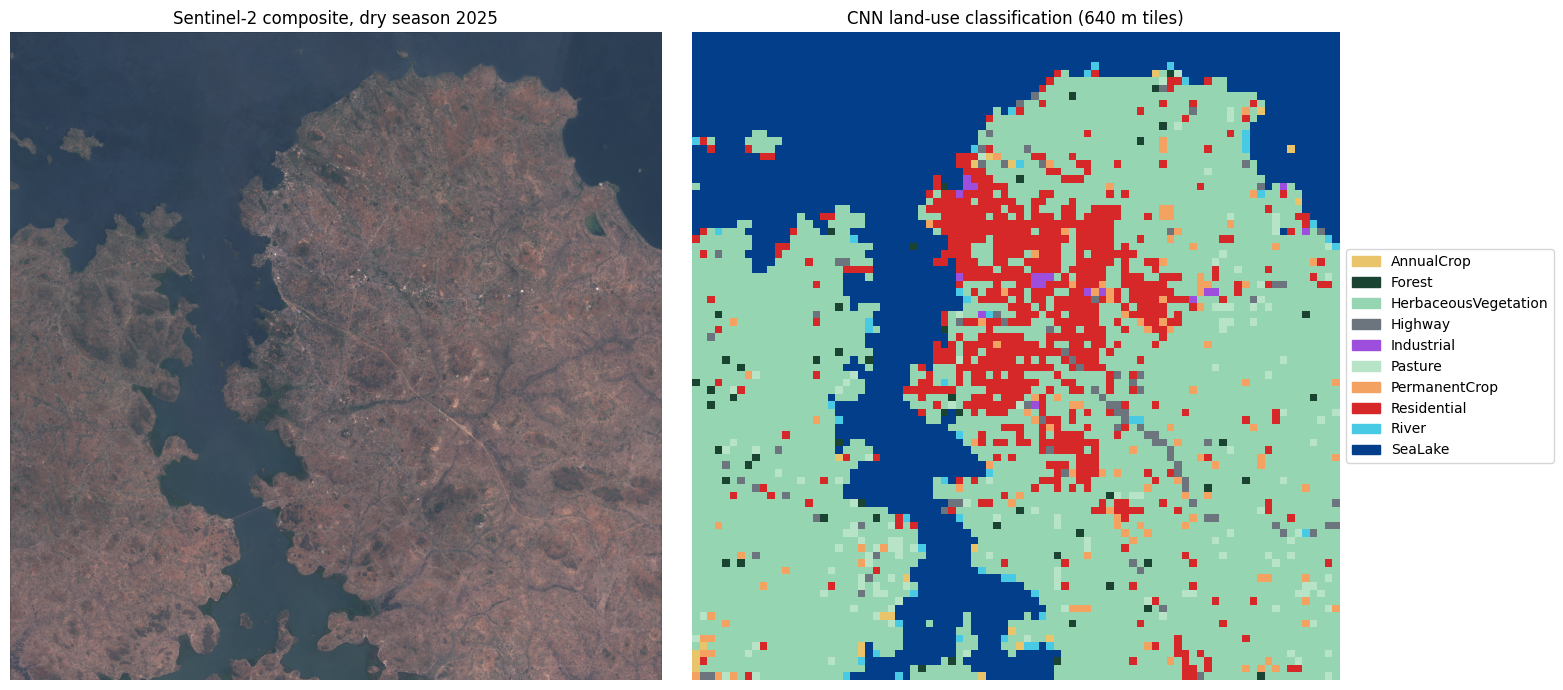

In [74]:
colors = ['#e9c46a', '#1b4332', '#95d5b2', '#6c757d', '#9d4edd',
          '#b7e4c7', '#f4a261', '#d62828', '#48cae4', '#023e8a']
grid = np.full((n_rows, n_cols), np.nan)
grid[df.row, df.col] = pred
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].imshow(img); ax[0].set_title('Sentinel-2 composite, dry season 2025')
ax[1].imshow(grid, cmap=ListedColormap(colors), vmin=-0.5, vmax=9.5,
             interpolation='nearest')
ax[1].set_title('CNN land-use classification (640 m tiles)')
ax[1].legend(handles=[Patch(color=colors[i], label=n) for i, n in enumerate(class_names)],
             loc='center left', bbox_to_anchor=(1, 0.5))
for a in ax: a.axis('off')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/mwanza_landuse_map.png', dpi=150, bbox_inches='tight')
plt.show()

### Step 6.10: Visual check: show 10 random tiles the model called "Residential".

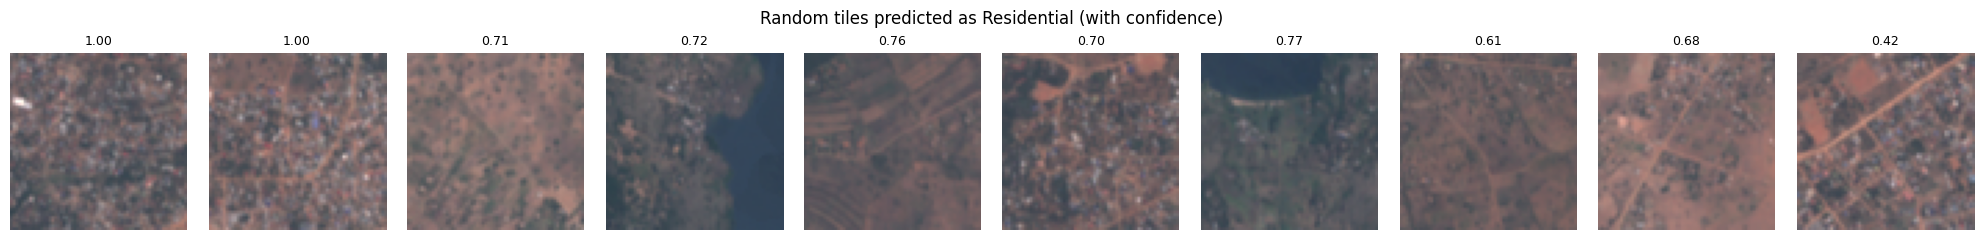

In [75]:
#     Look at them: do they really look like settlements?

res_idx = np.random.default_rng(1).choice(np.where(pred == 7)[0],
                                          min(10, (pred == 7).sum()), replace=False)
fig, axes = plt.subplots(1, len(res_idx), figsize=(2*len(res_idx), 2.4))
for a, i in zip(np.atleast_1d(axes), res_idx):
    a.imshow(tiles[i]); a.set_title(f"{probs[i].max():.2f}", fontsize=9); a.axis('off')
plt.suptitle('Random tiles predicted as Residential (with confidence)')
plt.tight_layout(); plt.show()

### Step 7: RECONNECT: restore everything after Colab reset

In [2]:
#    Connect Drive and install libraries.
from google.colab import drive
drive.mount('/content/drive')
!pip install -q rasterio geemap

import ee, rasterio, numpy as np, pandas as pd, matplotlib.pyplot as plt
from rasterio.warp import transform as warp_transform

#    Log back in to Earth Engine (same copy-the-code method as before;
#    choose your nm-aist account and tick all boxes).
ee.Authenticate(auth_mode='notebook')
ee.Initialize(project='lab-5-healthcare')

#    Reload our saved work and settings.
SAVE_DIR = '/content/drive/MyDrive/mwanza_project'
T = 64
AOI = ee.Geometry.Rectangle([32.70, -2.85, 33.20, -2.35])
df = pd.read_csv(f'{SAVE_DIR}/mwanza_tiles_classified.csv')
with rasterio.open(f'{SAVE_DIR}/mwanza_s2_rgb_2025.tif') as src:
    img = np.transpose(src.read(), (1, 2, 0))
    tfm, crs = src.transform, src.crs
n_rows, n_cols = img.shape[0] // T, img.shape[1] // T
print("Reconnected. Tiles loaded:", len(df))

#   Load the population table
df = pd.read_csv(f'{SAVE_DIR}/mwanza_tiles_population.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 90.1 MB/s eta 0:00:00
To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=64_R8Z1SysXS52NkqxfxjeJfb6HI7eu6lBMjNct6PUA&tc=YnTFOuLMLeCIFZgzfnJj5NrRW6oM9t-QgAw5NX-jYKA&cc=WPYNNKVeF1fipwyEkeCHoOG6Ozayz_FQQgx8SxnE5Q4

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AXlqoi56TVksO68ug6tpv2euRVUi4cTWsd7VoaAm3JG8S3Lc6n6N-iZIdE8

Succes

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Reconnected. Tiles loaded: 7396


### Step 8: Export Google Open Buildings for Mwanza

### Step 8.1: Load Google's building dataset and keep only buildings inside our study box.

In [77]:
#    confidence >= 0.75 -> keep only buildings Google's model is at least 75% sure of
#    (removes false detections such as rocks or shadows).

ob = (ee.FeatureCollection('GOOGLE/Research/open-buildings/v3/polygons') # "Load": open the full dataset (all 1.8 billion)
        .filterBounds(AOI)    # "keep only inside our study box"
        .filter(ee.Filter.gte('confidence', 0.75)))

### Step 8.2: Keep only 4 columns per building: its GPS position, its size, and confidence.

In [78]:
#    For EACH building: find the centre point of its outline,
#    then write that point's longitude and latitude into two normal columns.
#    (Each building is stored as a shape, so we calculate its centre ourselves.)

def to_point_row(f):
    xy = f.geometry().centroid(1).coordinates()      # [longitude, latitude]
    return ee.Feature(None, {
        'longitude': xy.get(0),
        'latitude': xy.get(1),
        'area_in_meters': f.get('area_in_meters'),
        'confidence': f.get('confidence'),
    })

ob_table = ob.map(to_point_row)

### Step 8.3: Export it as a CSV table to Drive (runs on Google's servers).

In [79]:
task_b = ee.batch.Export.table.toDrive(
    collection=ob_table,
    description='mwanza_buildings_points',
    folder='mwanza_project',
    fileNamePrefix='mwanza_buildings_points',
    fileFormat='CSV',
    selectors=['latitude', 'longitude', 'area_in_meters', 'confidence'])
task_b.start()

print("Building export started.")

Building export started.


### Step 8.3: Checking the export progress (READY -> RUNNING -> COMPLETED)

In [80]:
print(task_b.status()['state'])

READY


### Step 9: Buildings per tile -> population, and validate the CNN

### Step 9.1: Load the building list. Each row = one building.

In [81]:
#    Remove very small detections (< 15 m^2): usually sheds, kitchens or errors,
#    not houses.

b = pd.read_csv(f'{SAVE_DIR}/mwanza_buildings_points.csv')
b = b[b.area_in_meters >= 15]
print(f"Buildings in study area: {len(b):,}")

Buildings in study area: 364,622


### Step 9.2: Find which tile each building falls in.

In [82]:
#    a) Convert each building's GPS position into metres (same projection as our image).
#    b) Distance from the image's top-left corner / 640 m = the tile's row and column.

bx, by = warp_transform('EPSG:4326', crs, b.longitude.tolist(), b.latitude.tolist())
bx, by = np.array(bx), np.array(by)
x0, y0, px = tfm.c, tfm.f, tfm.a            # corner position (m) and pixel size (10 m)
b['col'] = ((bx - x0) // (px * T)).astype(int)
b['row'] = ((y0 - by) // (px * T)).astype(int)

### Step 9.3: Count buildings per tile and attach the count to our tile table.

In [83]:
counts = b.groupby(['row', 'col']).size().reset_index(name='buildings')
df = df.drop(columns=['buildings', 'population'], errors='ignore') \
       .merge(counts, on=['row', 'col'], how='left')
df['buildings'] = df['buildings'].fillna(0).astype(int)

print(f"Tiles with buildings: {df.buildings.sum():,}")

Tiles with buildings: 361,890


### Step 9.4: Estimate population: buildings x average household size.

In [84]:
#    4.3 = Tanzania's national average household size (2022 Census).
#    Assumption: roughly one household per building. Some buildings are
#    shops, schools or outbuildings, so this is an ESTIMATE of relative demand.

HH_SIZE = 4.3
df['population'] = (df['buildings'] * HH_SIZE).round()
print(f"Estimated population in study area: {df.population.sum():,.0f}")

Estimated population in study area: 1,556,153


### Step 9.5: VALIDATION A: average buildings per tile for each CNN class.

In [85]:
#    If the CNN is right, 'Residential' should have by far the most buildings
#    and 'SeaLake' almost zero.

print("\nBuildings per tile, by CNN land class:")
print(df.groupby('land_class')['buildings']
        .agg(tiles='count', mean='mean', median='median') # Checking Average buildings per tile (mean)
        .round(1).sort_values('mean', ascending=False))


Buildings per tile, by CNN land class:
                      tiles   mean  median
land_class                                
Residential             732  294.8   200.5
Industrial               19  181.6   126.0
Highway                  87   69.4    30.0
PermanentCrop           118   51.0    23.0
River                    50   46.4    10.5
HerbaceousVegetation   4050   30.0    11.0
AnnualCrop               22   28.4     4.0
Pasture                 133   16.0     8.0
Forest                   52   12.5     3.5
SeaLake                2133    1.5     0.0


### Step 9.6: VALIDATION B: can the CNN's Residential probability tell apart

In [86]:
#    settled and unsettled tiles?
#    "Settled" = at least 50 buildings in the tile (about 120 per km^2).
#    AUC = 0.5 means random guessing; 1.0 means perfect separation.

settled = df['buildings'] >= 50
auc = roc_auc_score(settled, df['p_residential'])
rho, _ = spearmanr(df['p_residential'], df['buildings'])
print(f"\nAUC (CNN Residential probability vs settled tiles): {auc:.3f}")
print(f"Spearman correlation (Residential probability vs building count): {rho:.3f}")


AUC (CNN Residential probability vs settled tiles): 0.913
Spearman correlation (Residential probability vs building count): 0.747


### Step 9.7: Side-by-side maps: CNN Residential probability vs estimated population.

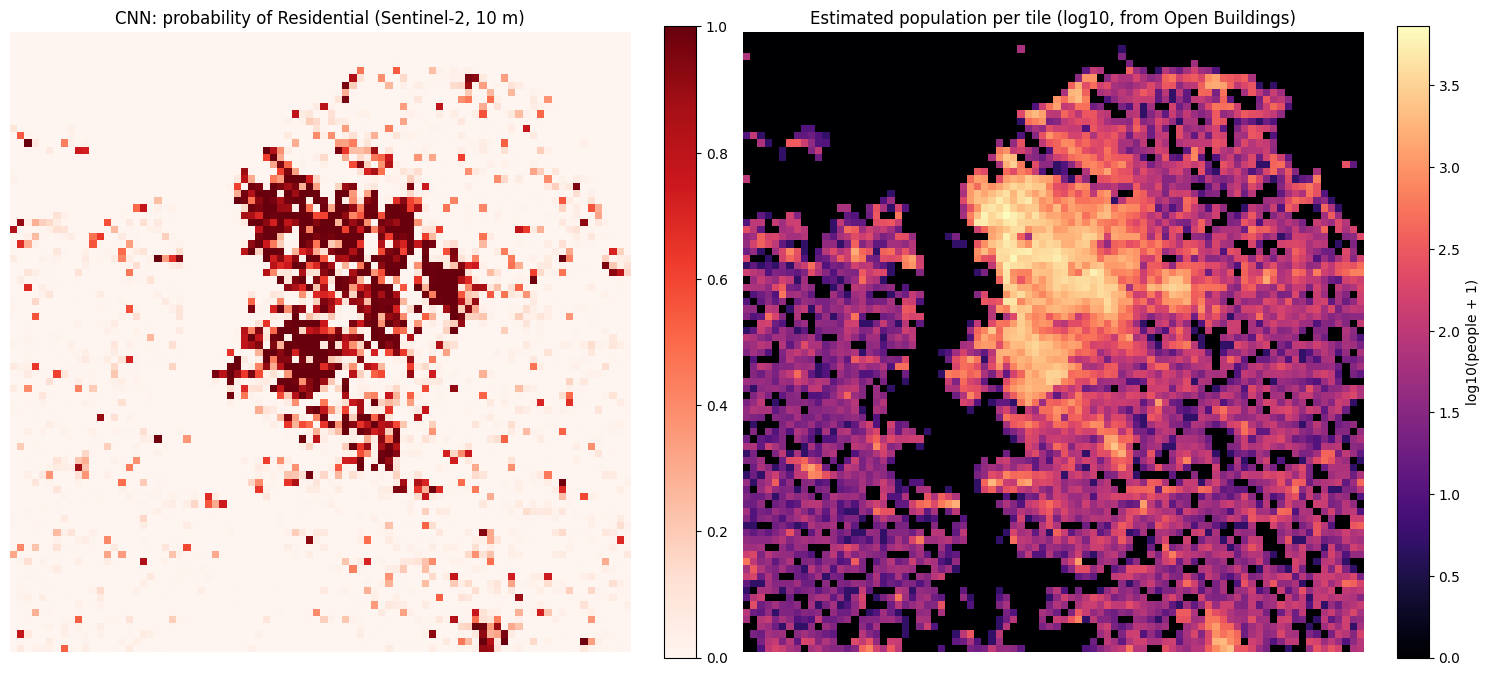

In [87]:
def to_grid(col):
    g = np.full((n_rows, n_cols), np.nan)
    g[df.row, df.col] = df[col]
    return g

fig, ax = plt.subplots(1, 2, figsize=(15, 7))
im0 = ax[0].imshow(to_grid('p_residential'), cmap='Reds', vmin=0, vmax=1)
ax[0].set_title('CNN: probability of Residential (Sentinel-2, 10 m)')
plt.colorbar(im0, ax=ax[0], fraction=0.046)
im1 = ax[1].imshow(np.log10(to_grid('population') + 1), cmap='magma')
ax[1].set_title('Estimated population per tile (log10, from Open Buildings)')
plt.colorbar(im1, ax=ax[1], fraction=0.046, label='log10(people + 1)')
for a in ax: a.axis('off')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/validation_population_maps.png', dpi=150, bbox_inches='tight')
plt.show()

### Step 9.8: Save the updated tile table (now with buildings and population).

In [88]:
df.to_csv(f'{SAVE_DIR}/mwanza_tiles_population.csv', index=False)
print("Saved mwanza_tiles_population.csv")

Saved mwanza_tiles_population.csv


## RESUME: run this after any Colab disconnect, then continue from Step 10

In [4]:
# Restores everything Steps 10-13 need from the files saved on Drive.
# No retraining, no Earth Engine login needed.

# 1. Install and import every library used from Step 10 onward.
!pip install -q rasterio pulp geopandas
import os, glob, zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
import pulp
from rasterio.warp import transform as warp_transform
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# 2. Connect Google Drive.
from google.colab import drive
drive.mount('/content/drive')

# 3. Settings used throughout.
SAVE_DIR = '/content/drive/MyDrive/mwanza_project'
T = 64                      # tile size in pixels (640 m)
LIMIT_KM = 5                # distance policy target (km)
class_names = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway',
               'Industrial', 'Pasture', 'PermanentCrop', 'Residential',
               'River', 'SeaLake']

# 4. Read the Mwanza image's position information (the "address book"),
#    so tile rows/columns can be converted to real positions again.
with rasterio.open(f'{SAVE_DIR}/mwanza_s2_rgb_2025.tif') as src:
    tfm, crs = src.transform, src.crs
    H, W = src.height, src.width
n_rows, n_cols = H // T, W // T

# 5. Load the tile table from Step 9 (CNN labels + buildings + population).
df = pd.read_csv(f'{SAVE_DIR}/mwanza_tiles_population.csv')

print(f"Resumed: {len(df)} tiles, grid {n_rows} x {n_cols}, "
      f"population {df.population.sum():,.0f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resumed: 7396 tiles, grid 86 x 86, population 1,556,153


### Step 10: Existing health facilities and distance to care

### Step 10.1: Unzip the HOT/OpenStreetMap files, find the .geojson inside, and read it.

In [10]:
#    Some facilities are mapped as a dot (points), others as a building
#    outline (polygons). For outlines we take a point inside the shape,
#    so every facility becomes one dot.

parts = []
for f in ['hotosm_tza_health_facilities_points_geojson.zip',
          'hotosm_tza_health_facilities_polygons_geojson.zip']:
    zpath = f'{SAVE_DIR}/{f}'
    print(f"{f}: {os.path.getsize(zpath)/1024:.0f} KB")   # a real zip is > ~50 KB
    out_dir = f'/content/hdx/{f[:-4]}'
    with zipfile.ZipFile(zpath) as z:
        print("   contains:", z.namelist())
        z.extractall(out_dir)
    gj = glob.glob(f'{out_dir}/**/*.geojson', recursive=True)[0]
    g = gpd.read_file(gj).to_crs('EPSG:4326')
    g['geometry'] = g.geometry.representative_point()
    parts.append(g)
    print(f"   read {len(g)} facilities")

g = pd.concat(parts, ignore_index=True)
g['lon'], g['lat'] = g.geometry.x, g.geometry.y

hotosm_tza_health_facilities_points_geojson.zip: 128 KB
   contains: ['hotosm_tza_health_facilities_points_geojson.geojson', 'Readme.txt']
   read 4148 facilities
hotosm_tza_health_facilities_polygons_geojson.zip: 214 KB
   contains: ['hotosm_tza_health_facilities_polygons_geojson.geojson', 'Readme.txt']
   read 2759 facilities


### Step 10.2: Keep only facilities inside our study box

In [11]:
#    (the same box as the satellite image: 32.70-33.20 E, 2.35-2.85 S).

g = g[g.lon.between(32.70, 33.20) & g.lat.between(-2.85, -2.35)]

### Step 10.3: Remove pharmacies and dentists

In [12]:
#    They sell medicine or treat teeth,
#    but are not general health facilities where people get primary care.

for col in ['amenity', 'healthcare']:
    if col not in g.columns:
        g[col] = None
g = g[~g.amenity.isin(['pharmacy', 'dentist']) &
      ~g.healthcare.isin(['pharmacy', 'dentist'])]

#     Also remove laboratories and drug shops (not places of primary care).
#     We check the NAME, because volunteers sometimes tag these as clinics.
bad_words = ['medical shop', 'laboratory', 'labaratory', ' lab', 'pharmacy', 'duka']
g = g[~g['name'].fillna('').str.lower().apply(lambda n: any(w in n for w in bad_words))]


### Step 10.4: Build a simple facility table: name, type, GPS position.

In [13]:
fac = pd.DataFrame({
    'name': g['name'].fillna('Unnamed').values,
    'amenity': g['amenity'].fillna(g['healthcare']).fillna('').values,
    'lat': g['lat'].values, 'lon': g['lon'].values})

### Step 10.5: Convert facility GPS positions to metres (same projection as our tiles)

In [14]:
#    so every distance we calculate is in real metres.

fx, fy = warp_transform('EPSG:4326', crs, fac.lon.tolist(), fac.lat.tolist())
fac['x_m'], fac['y_m'] = fx, fy

### Step 10.6: Remove duplicates

In [15]:
#    The same facility is sometimes mapped twice
#    (e.g. once as a dot and once as a building outline).
#    Rule: SAME NAME within 250 m = same facility.

t = cKDTree(fac[['x_m', 'y_m']].values)
drop = set()
for i, j in sorted(t.query_pairs(r=250)):          # all pairs closer than 250 m
    if i in drop or j in drop:
        continue
    if fac.name[i].strip().lower() == fac.name[j].strip().lower():
        drop.add(j)                                  # keep the first, drop the copy
fac = fac.drop(index=list(drop)).reset_index(drop=True)

print(f"Duplicates removed: {len(drop)}")

Duplicates removed: 37


### Step 10.7: Give each facility a level

In [16]:
#    Give each facility a level, like Tanzania's system:
#    Hospital > Health Centre > Dispensary/Clinic.
#    We read the name first ("Hospital", "Health Centre", "Kituo cha Afya"),
#    then fall back on the OSM tag.

def level(row):
    n = row['name'].lower()
    if any(k in n for k in ['dispensary', 'zahanati']):
        return 'Dispensary/Clinic'
    if any(k in n for k in ['health centre', 'health center', 'kituo']):
        return 'Health Centre'
    if any(k in n for k in ['hospital', 'hospitali', 'hosp.', 'medical centre']):
        return 'Hospital'
    if row['amenity'] == 'hospital':
        return 'Hospital'
    return 'Dispensary/Clinic'

fac['level'] = fac.apply(level, axis=1)
print(f"Health facilities in study area: {len(fac)}")
print(fac.level.value_counts(), "\n")
fac.to_csv(f'{SAVE_DIR}/mwanza_health_facilities_osm.csv', index=False)

Health facilities in study area: 157
level
Dispensary/Clinic    108
Hospital              37
Health Centre         12
Name: count, dtype: int64 



### Step 10.8: For EVERY tile, find the distance to the NEAREST facility.

In [17]:
#    cKDTree is a fast "nearest neighbour" search: instead of measuring every
#    tile against every facility one by one, it finds the closest one quickly.
#    Note: straight-line distance ("as the crow flies"), not road distance.

tree = cKDTree(fac[['x_m', 'y_m']].values)
dist_m, _ = tree.query(df[['x_m', 'y_m']].values)
df['dist_km'] = dist_m / 1000

### Step 10.9: Mark underserved tiles: people live there AND the nearest facility

In [18]:
#    is more than 5 km away (Tanzania's policy target: care within 5 km).

LIMIT_KM = 5
df['underserved'] = (df.population > 0) & (df.dist_km > LIMIT_KM)

total_pop = df.population.sum()
under_pop = df.loc[df.underserved, 'population'].sum()
print(f"Total estimated population:        {total_pop:,.0f}")
print(f"Population within {LIMIT_KM} km of care:   {total_pop - under_pop:,.0f} "
      f"({100 * (1 - under_pop / total_pop):.1f}%)")
print(f"UNDERSERVED population (> {LIMIT_KM} km):  {under_pop:,.0f} "
      f"({100 * under_pop / total_pop:.1f}%) in {df.underserved.sum()} tiles")

Total estimated population:        1,556,153
Population within 5 km of care:   1,518,413 (97.6%)
UNDERSERVED population (> 5 km):  37,740 (2.4%) in 458 tiles


### Step 10.10: Maps.

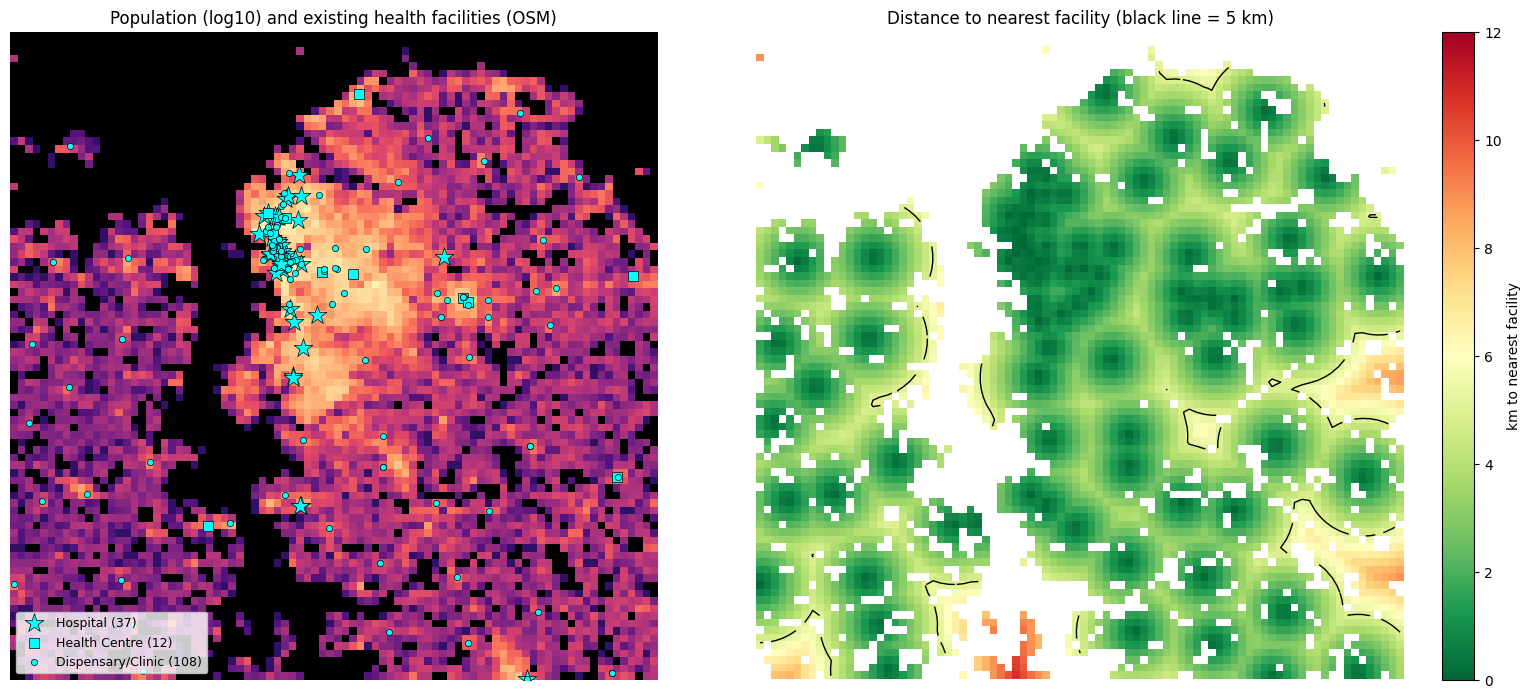

In [19]:
#     Left : population, with existing facilities drawn on top.
#     Right: distance to the nearest facility (green = close, red = far);
#            the black line marks the 5 km limit.

def to_grid(col):
    grid = np.full((n_rows, n_cols), np.nan)
    grid[df.row, df.col] = df[col]
    return grid

# facility positions in grid units, so the dots line up with the tile maps
fac_c = (fac.x_m - tfm.c) / (tfm.a * T) - 0.5
fac_r = (tfm.f - fac.y_m) / (tfm.a * T) - 0.5
marker = {'Hospital': ('*', 200), 'Health Centre': ('s', 50),
          'Dispensary/Clinic': ('o', 20)}

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].imshow(np.log10(to_grid('population') + 1), cmap='magma')
for lv, (m, s) in marker.items():
    sel = fac.level == lv
    ax[0].scatter(fac_c[sel], fac_r[sel], marker=m, s=s, c='cyan',
                  edgecolors='k', linewidths=0.5, label=f'{lv} ({sel.sum()})')
ax[0].legend(loc='lower left', fontsize=9)
ax[0].set_title('Population (log10) and existing health facilities (OSM)')

dgrid = to_grid('dist_km')
dgrid[to_grid('population') == 0] = np.nan          # hide empty tiles (e.g. lake)
im = ax[1].imshow(dgrid, cmap='RdYlGn_r', vmin=0, vmax=12)
ax[1].contour(dgrid, levels=[LIMIT_KM], colors='k', linewidths=1)
plt.colorbar(im, ax=ax[1], fraction=0.046, label='km to nearest facility')
ax[1].set_title(f'Distance to nearest facility (black line = {LIMIT_KM} km)')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/access_gap_maps.png', dpi=150, bbox_inches='tight')
plt.show()

### Step 10.11: Save the tile table, now with distance and the underserved flag.

In [20]:
#     This table is the input for the optimization in Step 8.

df.to_csv(f'{SAVE_DIR}/mwanza_tiles_access.csv', index=False)
print("Saved mwanza_tiles_access.csv")

Saved mwanza_tiles_access.csv


### Step 10.12: Quick check: list the hospitals found (are the big ones there?).

In [21]:
print("\nHospitals found:")
print(fac[fac.level == 'Hospital'][['name', 'lat', 'lon']].to_string(index=False))


Hospitals found:
                       name       lat       lon
           Government Hosp. -2.509796 32.904250
                    Unnamed -2.478618 32.910705
                   Hospital -2.476002 32.912185
             Neema Hospital -2.491630 32.893710
                CF Hospital -2.521306 32.898462
Dr Chacha Memorial Hospital -2.521059 32.898464
             Uhuru Hospital -2.572963 32.916982
                    Unnamed -2.460023 32.921107
                    Unnamed -2.524536 32.917979
Nyamagana District Hospital -2.563094 32.914144
              MENT Hospital -2.494461 32.919879
             Uhuru hospital -2.520691 32.911048
            Mwanza hospital -2.476025 32.922340
     Bugando Medical Centre -2.527664 32.907494
       Hindu Union Hospital -2.532721 32.908786
           Bukumbi Hospital -2.714675 32.922481
      Mpango Wa Damu Salama -2.529645 32.906840
            Mwanza Hospital -2.518716 32.907541
        Bugando Town Clinic -2.508341 32.900443
                    Un

### Step 11: Stage 1 optimization - maximise access (MCLP)

### Step 11.1: DEMAND = the underserved tiles (people living > 5 km from any facility).

In [22]:
dem = df[df.underserved].reset_index(drop=True)
print(f"Underserved tiles: {len(dem)}  |  people: {dem.population.sum():,.0f}")

Underserved tiles: 458  |  people: 37,740


### Step 11.2: CANDIDATE SITES = where a new facility COULD be built.

In [23]:
#    a) Must be on land: we use the CNN labels to exclude water tiles
#       (SeaLake, River). This is where the image analysis feeds the optimization.
#    b) Must be within 5 km of at least one underserved tile
#       (a site far from everyone who needs it is pointless).

land = df[~df.land_class.isin(['SeaLake', 'River'])].reset_index(drop=True)
tree_land = cKDTree(land[['x_m', 'y_m']].values)
near = tree_land.query_ball_point(dem[['x_m', 'y_m']].values, r=LIMIT_KM * 1000)
cand = land.loc[sorted({j for lst in near for j in lst})].reset_index(drop=True)
print(f"Candidate sites (land tiles near underserved people): {len(cand)}")

Candidate sites (land tiles near underserved people): 2837


### Step 11.3: COVERAGE LISTS

In [24]:
#    For each underserved tile, which candidate sites are
#    within 5 km? (If we build at any of them, this tile becomes covered.)

tree_cand = cKDTree(cand[['x_m', 'y_m']].values)
cover = tree_cand.query_ball_point(dem[['x_m', 'y_m']].values, r=LIMIT_KM * 1000)

### Step 11.4: The optimization model, written as a function of the budget K.

In [25]:
def solve_stage1(K):
    prob = pulp.LpProblem('Stage1_Access', pulp.LpMaximize)

    # Decisions: build[j] = 1 if we build at site j;  covered[i] = 1 if tile i is covered
    build   = pulp.LpVariable.dicts('build', range(len(cand)), cat='Binary')
    covered = pulp.LpVariable.dicts('covered', range(len(dem)), cat='Binary')

    # Goal: maximise the number of underserved PEOPLE covered
    prob += pulp.lpSum(dem.population[i] * covered[i] for i in range(len(dem)))

    # Rule 1: a tile is covered only if at least one chosen site is within 5 km
    for i in range(len(dem)):
        prob += covered[i] <= pulp.lpSum(build[j] for j in cover[i])

    # Rule 2 (budget): build at most K new facilities
    prob += pulp.lpSum(build.values()) <= K

    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=120))
    chosen = [j for j in range(len(cand)) if build[j].value() > 0.5]
    people = sum(dem.population[i] for i in range(len(dem)) if covered[i].value() > 0.5)
    return chosen, people

### Step 11.5: Try budgets of 1 to 10 facilities, to see how much each extra facility adds ("diminishing returns").

K =  1 new facilities ->   10,132 people covered ( 26.8% of underserved)
K =  2 new facilities ->   16,186 people covered ( 42.9% of underserved)
K =  3 new facilities ->   21,174 people covered ( 56.1% of underserved)
K =  4 new facilities ->   24,648 people covered ( 65.3% of underserved)
K =  5 new facilities ->   27,542 people covered ( 73.0% of underserved)
K =  6 new facilities ->   30,243 people covered ( 80.1% of underserved)
K =  7 new facilities ->   32,660 people covered ( 86.5% of underserved)
K =  8 new facilities ->   34,345 people covered ( 91.0% of underserved)
K =  9 new facilities ->   35,889 people covered ( 95.1% of underserved)
K = 10 new facilities ->   36,518 people covered ( 96.8% of underserved)


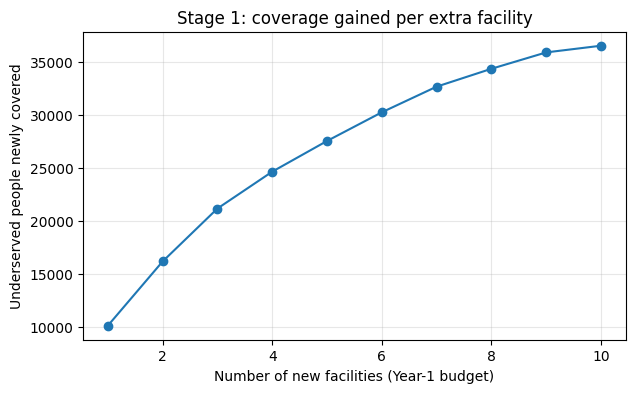

In [26]:
results = []
for K in range(1, 11):
    chosen, people = solve_stage1(K)
    results.append((K, people))
    print(f"K = {K:2d} new facilities -> {people:8,.0f} people covered "
          f"({100 * people / dem.population.sum():5.1f}% of underserved)")

ks, ppl = zip(*results)
plt.figure(figsize=(7, 4))
plt.plot(ks, ppl, 'o-')
plt.xlabel('Number of new facilities (Year-1 budget)')
plt.ylabel('Underserved people newly covered')
plt.title('Stage 1: coverage gained per extra facility')
plt.grid(alpha=0.3)
plt.savefig(f'{SAVE_DIR}/stage1_budget_curve.png', dpi=150, bbox_inches='tight')
plt.show()

### Step 11.6: Stage 1 final plan (K = 6)

In [27]:
K1 = 6
chosen, people = solve_stage1(K1)

### Step 11.7: Table of the chosen sites

In [28]:
#    Position, CNN land class, and how many
#    underserved people live within 5 km of each site.

new1 = cand.loc[chosen, ['row', 'col', 'x_m', 'y_m', 'lon', 'lat', 'land_class']].copy()
tree_dem = cKDTree(dem[['x_m', 'y_m']].values)
new1['underserved_within_5km'] = [
    dem.population[idx].sum()
    for idx in tree_dem.query_ball_point(new1[['x_m', 'y_m']].values, r=LIMIT_KM * 1000)]
new1['name']  = [f'New Dispensary S1-{i+1}' for i in range(len(new1))]
new1['level'] = 'Dispensary/Clinic'
new1['stage'] = 1
new1 = new1.sort_values('underserved_within_5km', ascending=False).reset_index(drop=True)
print(f"Stage 1 plan: {K1} new dispensaries, covering {people:,.0f} underserved people\n")
print(new1[['name', 'lat', 'lon', 'land_class', 'underserved_within_5km']].to_string(index=False))
new1.to_csv(f'{SAVE_DIR}/stage1_new_facilities.csv', index=False)

Stage 1 plan: 6 new dispensaries, covering 30,243 underserved people

               name       lat       lon           land_class  underserved_within_5km
New Dispensary S1-5 -2.763922 33.157630 HerbaceousVegetation                 10132.0
New Dispensary S1-2 -2.613379 33.157610 HerbaceousVegetation                  6054.0
New Dispensary S1-1 -2.555474 32.817929 HerbaceousVegetation                  4473.0
New Dispensary S1-3 -2.630752 32.863978 HerbaceousVegetation                  4088.0
New Dispensary S1-6 -2.804458 32.881234 HerbaceousVegetation                  2894.0
New Dispensary S1-4 -2.630758 33.053977 HerbaceousVegetation                  2701.0


### Step 11.8: Add the new facilities to the existing ones, and recalculate every tile's distance to its nearest facility AFTER Stage 1.

In [29]:
fac_all = pd.concat([fac.assign(stage=0),
                     new1[['name', 'level', 'lat', 'lon', 'x_m', 'y_m', 'stage']]],
                    ignore_index=True)
d1, _ = cKDTree(fac_all[['x_m', 'y_m']].values).query(df[['x_m', 'y_m']].values)
df['dist_km_s1']     = d1 / 1000
df['underserved_s1'] = (df.population > 0) & (df.dist_km_s1 > LIMIT_KM)

before = df.loc[df.underserved, 'population'].sum()
after  = df.loc[df.underserved_s1, 'population'].sum()
print(f"\nUnderserved BEFORE Stage 1: {before:,.0f} people ({100*before/total_pop:.1f}%)")
print(f"Underserved AFTER  Stage 1: {after:,.0f} people ({100*after/total_pop:.1f}%)")
print(f"Access within 5 km: {100*(1-before/total_pop):.1f}% -> {100*(1-after/total_pop):.1f}%")


Underserved BEFORE Stage 1: 37,740 people (2.4%)
Underserved AFTER  Stage 1: 7,497 people (0.5%)
Access within 5 km: 97.6% -> 99.5%


### Step 11.9: Mapping

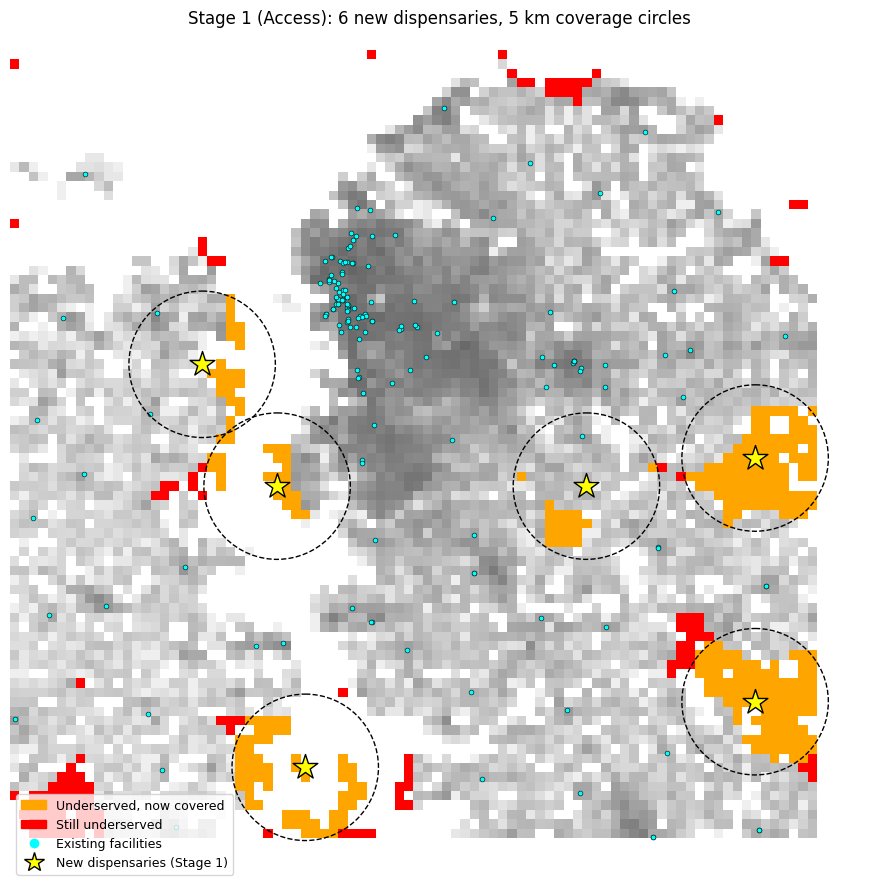

In [30]:
#    Map: underserved tiles before (orange) and still underserved after (red),
#    existing facilities (cyan), new Stage-1 sites (yellow stars + 5 km circles).
def to_grid(col):
    grid = np.full((n_rows, n_cols), np.nan)
    grid[df.row, df.col] = df[col]
    return grid

status = np.where(df.underserved_s1, 2, np.where(df.underserved, 1, 0)).astype(float)
df['_status'] = status
sgrid = to_grid('_status')
sgrid[to_grid('population') == 0] = np.nan

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(np.log10(to_grid('population') + 1), cmap='Greys', alpha=0.6)
ax.imshow(np.where(sgrid >= 1, sgrid, np.nan),
          cmap=ListedColormap(['orange', 'red']), vmin=0.5, vmax=2.5)

fc = (fac.x_m - tfm.c) / (tfm.a * T) - 0.5
fr = (tfm.f - fac.y_m) / (tfm.a * T) - 0.5
ax.scatter(fc, fr, s=12, c='cyan', edgecolors='k', linewidths=0.4, label='Existing facilities')

nc, nr = new1.col.values, new1.row.values
ax.scatter(nc, nr, marker='*', s=350, c='yellow', edgecolors='k', label='New dispensaries (Stage 1)')
radius_tiles = LIMIT_KM * 1000 / (tfm.a * T)          # 5 km in tile units (~7.8)
for c, r in zip(nc, nr):
    ax.add_patch(plt.Circle((c, r), radius_tiles, fill=False, ls='--', color='k', lw=1))

ax.legend(handles=[Patch(color='orange', label='Underserved, now covered'),
                   Patch(color='red', label='Still underserved'),
                   plt.Line2D([], [], marker='o', ls='', color='cyan', label='Existing facilities'),
                   plt.Line2D([], [], marker='*', ls='', color='yellow', markersize=15,
                              markeredgecolor='k', label='New dispensaries (Stage 1)')],
          loc='lower left', fontsize=9)
ax.set_title(f'Stage 1 (Access): {K1} new dispensaries, 5 km coverage circles')
ax.axis('off')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/stage1_plan_map.png', dpi=150, bbox_inches='tight')
plt.show()

df = df.drop(columns='_status')
df.to_csv(f'{SAVE_DIR}/mwanza_tiles_stage1.csv', index=False)
fac_all.to_csv(f'{SAVE_DIR}/facilities_after_stage1.csv', index=False)

### Step 12: Stage 2 - capacity, with flexible facility choice

### Step 12.1: Assumptions

In [31]:
# ---------- Assumptions (We will change if there is any official figures available) ----------
BASE_CAP = {'Dispensary/Clinic': 10_000, 'Health Centre': 50_000, 'Hospital': 150_000}
COST_STAFF, CAP_STAFF, MAX_STAFF = 1, 5_000, 4   # clinician: 1 unit, +5,000, max 4 per facility
COST_UPG,   CAP_UPG              = 6, 40_000     # dispensary -> health centre: 6 units, +40,000
CHOICES = 5                                       # people may use any of their 5 nearest facilities...
                                                  # ...that are within 5 km
# -----------------------------------------------------------------------------

### Step 12.2: Remove entries that are not places of primary care (shops, labs, pharmacies).

In [32]:
fac_all = fac_all.reset_index(drop=True)
fac_all.loc[fac_all.stage == 1, 'name'] = [f'New Dispensary S1-{i+1}' for i in range(K1)]
bad_words = ['medical shop', 'laboratory', ' lab', 'pharmacy', 'duka']
is_bad = (fac_all.stage == 0) & fac_all.name.str.lower().apply(
            lambda n: any(w in n for w in bad_words))
print("Removed (not care facilities):", fac_all.loc[is_bad, 'name'].tolist())
fac2 = fac_all[~is_bad].reset_index(drop=True)
fac2['capacity'] = fac2.level.map(BASE_CAP)
print(f"Facilities used in Stage 2: {len(fac2)}  "
      f"(incl. {int((fac2.stage == 1).sum())} built in Stage 1)")

Removed (not care facilities): []
Facilities used in Stage 2: 163  (incl. 6 built in Stage 1)


### Step 12.3: For every populated tile, list the facilities its people are ALLOWED to use.

In [33]:
#    Its 5 nearest facilities, keeping only those within 5 km.
#    (If none is within 5 km, the tile may use only its single nearest facility.)

pt = df[df.population > 0].reset_index(drop=True)
dists, idxs = cKDTree(fac2[['x_m', 'y_m']].values).query(pt[['x_m', 'y_m']].values, k=CHOICES)
options = []
for d_row, f_row in zip(dists, idxs):
    ok = [int(f) for d, f in zip(d_row, f_row) if d <= LIMIT_KM * 1000]
    options.append(ok if ok else [int(f_row[0])])

### Step 12.4: The Stage-2 model, as a function of the Year-2 budget B.

In [34]:
def solve_stage2(B):
    prob = pulp.LpProblem('Stage2_Capacity', pulp.LpMinimize)
    I, F = range(len(pt)), range(len(fac2))

    # Decisions:
    #   send[i,f] = how many people from tile i are served at facility f
    #   unmet[i]  = people in tile i who cannot be served anywhere
    #   staff[f]  = extra clinicians at facility f (0..4)
    #   upg[f]    = 1 if dispensary f is upgraded to a health centre
    send  = {(i, f): pulp.LpVariable(f's_{i}_{f}', lowBound=0) for i in I for f in options[i]}
    unmet = pulp.LpVariable.dicts('unmet', I, lowBound=0)
    staff = pulp.LpVariable.dicts('staff', F, 0, MAX_STAFF, cat='Integer')
    upg   = pulp.LpVariable.dicts('upg', F, cat='Binary')

    # Goal: MINIMISE unserved people first; among equally good plans, choose the
    # cheapest (0.001 is so small it never trades a person for money).
    prob += (pulp.lpSum(unmet.values())
             + 0.001 * pulp.lpSum(COST_STAFF * staff[f] + COST_UPG * upg[f] for f in F))

    # Rule 1: every person in a tile is either served somewhere, or unmet
    for i in I:
        prob += pulp.lpSum(send[i, f] for f in options[i]) + unmet[i] == pt.population[i]

    # Rule 2: a facility cannot serve more people than its capacity
    #         (base capacity + extra clinicians + upgrade)
    users = {f: [] for f in F}
    for (i, f) in send:
        users[f].append(i)
    for f in F:
        prob += (pulp.lpSum(send[i, f] for i in users[f])
                 <= fac2.capacity[f] + CAP_STAFF * staff[f] + CAP_UPG * upg[f])
        # Rule 3: only dispensaries/clinics can be upgraded
        if fac2.level[f] != 'Dispensary/Clinic':
            prob += upg[f] == 0

    # Rule 4 (budget): total spending must not exceed B
    prob += pulp.lpSum(COST_STAFF * staff[f] + COST_UPG * upg[f] for f in F) <= B

    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=180))

    plan = fac2[['name', 'level', 'stage', 'capacity']].copy()
    plan['served']      = [sum(send[i, f].value() for i in users[f]) for f in F]
    plan['extra_staff'] = [int(round(staff[f].value())) for f in F]
    plan['upgrade']     = [int(round(upg[f].value())) for f in F]
    unmet_tile = np.array([unmet[i].value() for i in I])
    return plan, unmet_tile, pulp.LpStatus[prob.status]

### Step 12.5: Try several budgets (this takes a few minutes: each run is a full optimization).

Budget  0 units -> unmet demand    91,216 people  [Optimal]
Budget 10 units -> unmet demand    31,216 people  [Optimal]
Budget 20 units -> unmet demand         0 people  [Optimal]
Budget 30 units -> unmet demand         0 people  [Optimal]
Budget 40 units -> unmet demand         0 people  [Optimal]
Budget 60 units -> unmet demand         0 people  [Optimal]
Budget 80 units -> unmet demand         0 people  [Optimal]


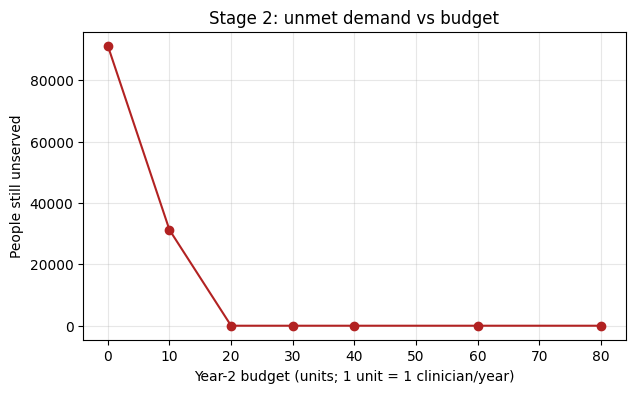

In [35]:
curve = []
for B in [0, 10, 20, 30, 40, 60, 80]:
    _, u, status = solve_stage2(B)
    curve.append((B, u.sum()))
    print(f"Budget {B:2d} units -> unmet demand {u.sum():9,.0f} people  [{status}]")

plt.figure(figsize=(7, 4))
plt.plot(*zip(*curve), 'o-', color='firebrick')
plt.xlabel('Year-2 budget (units; 1 unit = 1 clinician/year)')
plt.ylabel('People still unserved')
plt.title('Stage 2: unmet demand vs budget')
plt.grid(alpha=0.3)
plt.savefig(f'{SAVE_DIR}/stage2_budget_curve.png', dpi=150, bbox_inches='tight')
plt.show()

### Step 12.6: Smallest budget that closes the gap + final Stage 2 plan

### Step 12.7: Test budgets 0, 2, 4, ... 20 to find the SMALLEST one that serves everyone.

Budget  0 units -> unmet   91,216 people
Budget  2 units -> unmet   81,216 people
Budget  4 units -> unmet   71,216 people
Budget  6 units -> unmet   51,216 people
Budget  8 units -> unmet   41,216 people
Budget 10 units -> unmet   31,216 people
Budget 12 units -> unmet   12,441 people
Budget 14 units -> unmet    2,441 people
Budget 16 units -> unmet        0 people
Budget 18 units -> unmet        0 people
Budget 20 units -> unmet        0 people

Smallest budget that closes the capacity gap: 16 units


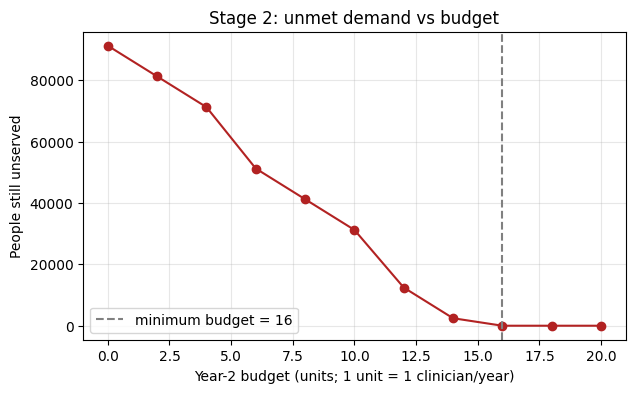

In [36]:
fine = []
for B in range(0, 21, 2):
    _, u, _ = solve_stage2(B)
    fine.append((B, u.sum()))
    print(f"Budget {B:2d} units -> unmet {u.sum():8,.0f} people")
B2 = next((B for B, u in fine if u < 1), 20)
print(f"\nSmallest budget that closes the capacity gap: {B2} units")

plt.figure(figsize=(7, 4))
plt.plot(*zip(*fine), 'o-', color='firebrick')
plt.axvline(B2, color='grey', ls='--', label=f'minimum budget = {B2}')
plt.xlabel('Year-2 budget (units; 1 unit = 1 clinician/year)')
plt.ylabel('People still unserved')
plt.title('Stage 2: unmet demand vs budget')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(f'{SAVE_DIR}/stage2_budget_curve.png', dpi=150, bbox_inches='tight')
plt.show()

### Step 12.8: The final Stage 2 plan at that budget.

In [37]:
plan2, unmet2, status = solve_stage2(B2)
_, unmet0, _ = solve_stage2(0)                # the gap BEFORE Stage 2 (for the map)
acts = plan2[(plan2.extra_staff > 0) | (plan2.upgrade > 0)] \
         .sort_values(['upgrade', 'extra_staff'], ascending=False)
spent = COST_STAFF * acts.extra_staff.sum() + COST_UPG * acts.upgrade.sum()
print(f"\nSTAGE 2 PLAN [{status}]: {int(acts.extra_staff.sum())} extra clinicians, "
      f"{int(acts.upgrade.sum())} upgrades, total cost {spent} units")
print(f"Unserved people: {unmet0.sum():,.0f} -> {unmet2.sum():,.0f}\n")
print(acts[['name', 'level', 'stage', 'capacity', 'served', 'extra_staff', 'upgrade']]
        .round(0).to_string(index=False))
plan2.to_csv(f'{SAVE_DIR}/stage2_plan.csv', index=False)


STAGE 2 PLAN [Optimal]: 4 extra clinicians, 2 upgrades, total cost 16 units
Unserved people: 91,216 -> 0

               name             level  stage  capacity  served  extra_staff  upgrade
  Mwanza Dispensary Dispensary/Clinic      0     10000 45778.0            0        1
 Nyerere Dispensary Dispensary/Clinic      0     10000 50000.0            0        1
  Lutale Dispensary Dispensary/Clinic      0     10000 20000.0            2        0
  Igogwe Dispensary Dispensary/Clinic      0     10000 15000.0            1        0
New Dispensary S1-1 Dispensary/Clinic      1     10000 11859.0            1        0


### Step 12.9: Map: where the capacity gap was (red), and what Stage 2 does about it.

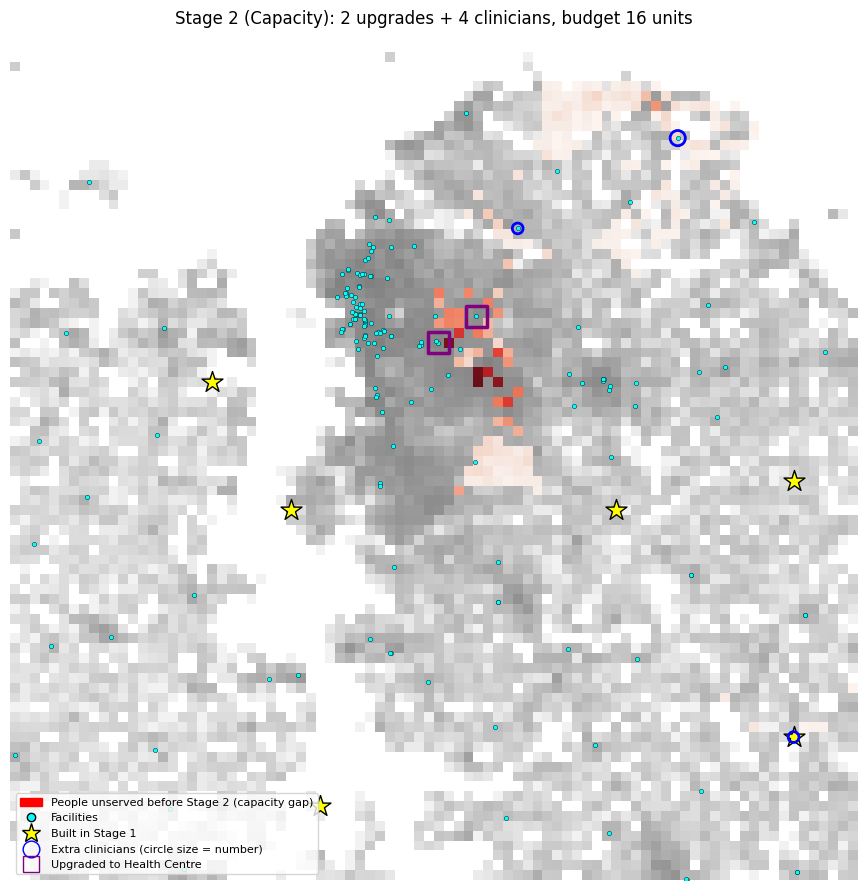

In [38]:
def to_grid_from(frame, col):
    g = np.full((n_rows, n_cols), np.nan)
    g[frame.row, frame.col] = frame[col]
    return g

pt['unmet0'] = unmet0
gap = to_grid_from(pt, 'unmet0')
gap[gap <= 0.5] = np.nan
pop_g = to_grid_from(df, 'population')

fc = (fac2.x_m - tfm.c) / (tfm.a * T) - 0.5
fr = (tfm.f - fac2.y_m) / (tfm.a * T) - 0.5
up = plan2.upgrade.values == 1
st = plan2.extra_staff.values
s1 = fac2.stage.values == 1

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(np.log10(pop_g + 1), cmap='Greys', alpha=0.5)
ax.imshow(gap, cmap='Reds', alpha=0.9)
ax.scatter(fc, fr, s=10, c='cyan', edgecolors='k', linewidths=0.3)
ax.scatter(fc[s1], fr[s1], marker='*', s=250, c='yellow', edgecolors='k')
ax.scatter(fc[st > 0], fr[st > 0], s=60 * st[st > 0], facecolors='none',
           edgecolors='blue', linewidths=2)
ax.scatter(fc[up], fr[up], marker='s', s=220, facecolors='none',
           edgecolors='purple', linewidths=2.5)
ax.legend(handles=[
    Patch(color='red', label='People unserved before Stage 2 (capacity gap)'),
    plt.Line2D([], [], marker='o', ls='', color='cyan', markeredgecolor='k', label='Facilities'),
    plt.Line2D([], [], marker='*', ls='', color='yellow', markersize=14,
               markeredgecolor='k', label='Built in Stage 1'),
    plt.Line2D([], [], marker='o', ls='', markerfacecolor='none', markeredgecolor='blue',
               markersize=12, label='Extra clinicians (circle size = number)'),
    plt.Line2D([], [], marker='s', ls='', markerfacecolor='none', markeredgecolor='purple',
               markersize=12, label='Upgraded to Health Centre')],
    loc='lower left', fontsize=8)
ax.set_title(f'Stage 2 (Capacity): {int(acts.upgrade.sum())} upgrades + '
             f'{int(acts.extra_staff.sum())} clinicians, budget {B2} units')
ax.axis('off')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/stage2_plan_map.png', dpi=150, bbox_inches='tight')
plt.show()

### Step 13: Compare our plan with simpler strategies (same budgets)

In [39]:
rng = np.random.default_rng(42)

### Step 13.1: Where to put 6 new dispensaries

In [40]:
# How many underserved people are within 5 km of a set of sites?

def covered_pop(xy):
    idx = set()
    for lst in tree_dem.query_ball_point(xy, r=LIMIT_KM * 1000):
        idx.update(lst)
    return dem.population[list(idx)].sum()

s1_opt = covered_pop(new1[['x_m', 'y_m']].values)                       # our optimized plan
top6   = dem.nlargest(K1, 'population')                                 # common-sense rule
s1_top = covered_pop(top6[['x_m', 'y_m']].values)
s1_rnd = np.mean([covered_pop(cand.sample(K1, random_state=int(s))[['x_m', 'y_m']].values)
                  for s in rng.integers(0, 10**6, 200)])                # random sites


 ### Step 13.2: How to spend 16 units

STAGE 1 - 6 new dispensaries (out of 37,740 underserved)
                  Strategy  Underserved people covered
      Optimized (our plan)                     30243.0
Most-populated tiles first                     12853.0
              Random sites                      8828.0

STAGE 2 - budget 16 units (capacity gap before Stage 2: 91,216)
                         Strategy  People still unserved
Optimized, multi-stage (our plan)                    0.0
         Myopic (ignores Stage 1)                 2441.0
        1 clinician to 16 busiest                41216.0
         1 clinician to 16 random                77787.0


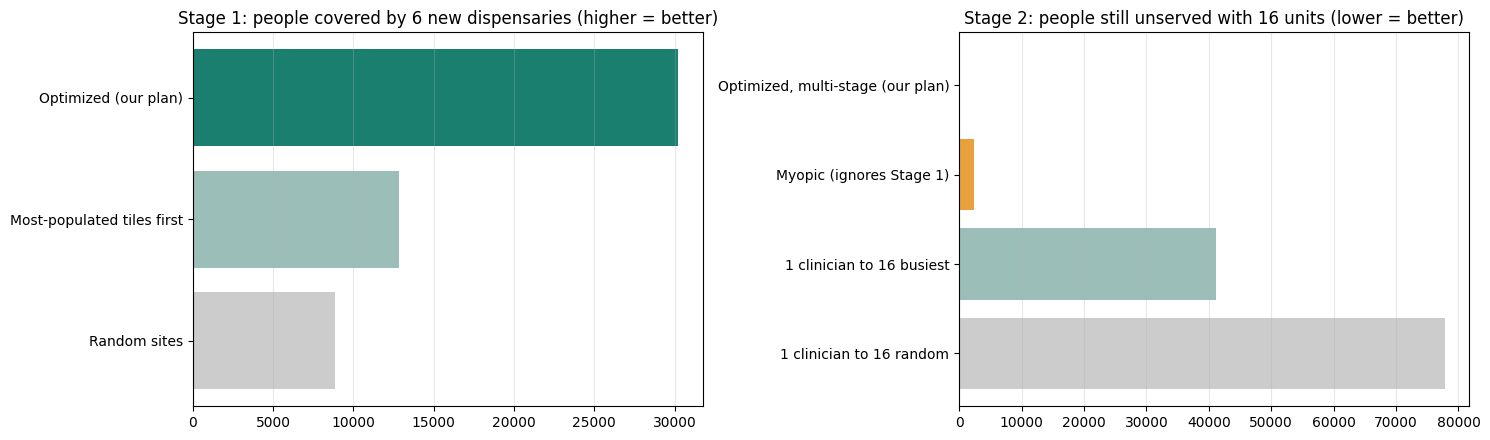

In [41]:
# Given each facility's FINAL capacity, how many people are left unserved?
# (People may still use any of their 5 nearest facilities within 5 km.)

def unmet_given(facs, opts, extra_cap):
    prob = pulp.LpProblem('evaluate', pulp.LpMinimize)
    I, F = range(len(pt)), range(len(facs))
    send  = {(i, f): pulp.LpVariable(f's_{i}_{f}', lowBound=0) for i in I for f in opts[i]}
    unmet = pulp.LpVariable.dicts('u', I, lowBound=0)
    prob += pulp.lpSum(unmet.values())
    for i in I:
        prob += pulp.lpSum(send[i, f] for f in opts[i]) + unmet[i] == pt.population[i]
    users = {f: [] for f in F}
    for (i, f) in send:
        users[f].append(i)
    cap = facs.level.map(BASE_CAP).values + extra_cap
    for f in F:
        prob += pulp.lpSum(send[i, f] for i in users[f]) <= cap[f]
    prob.solve(pulp.PULP_CBC_CMD(msg=0))
    return sum(v.value() for v in unmet.values())

nF = len(fac2)

# a) Our optimized plan
extra_opt = CAP_STAFF * plan2.extra_staff.values + CAP_UPG * plan2.upgrade.values
s2_opt = unmet_given(fac2, options, extra_opt)

# b) Common-sense rule: 1 clinician each to the 16 BUSIEST facilities
#    (busiest = most people for whom it is the nearest facility)
_, nn = cKDTree(fac2[['x_m', 'y_m']].values).query(pt[['x_m', 'y_m']].values)
busy = np.bincount(nn, weights=pt.population.values, minlength=nF)
extra_busy = np.zeros(nF); extra_busy[np.argsort(busy)[::-1][:B2]] = CAP_STAFF
s2_busy = unmet_given(fac2, options, extra_busy)

# c) No planning: 1 clinician each to 16 RANDOM facilities (average of 20 tries)
s2_rnd = []
for s in range(20):
    e = np.zeros(nF); e[rng.choice(nF, B2, replace=False)] = CAP_STAFF
    s2_rnd.append(unmet_given(fac2, options, e))
s2_rnd = np.mean(s2_rnd)

# d) MYOPIC: Stage 2 planned as if Stage 1 never happened, then applied to the
#    real situation (where the 6 new dispensaries DO exist).
fac_old = fac2[fac2.stage == 0].reset_index(drop=True)
n_old = len(fac_old)
def build_options(facs):
    d, ix = cKDTree(facs[['x_m', 'y_m']].values).query(pt[['x_m', 'y_m']].values, k=CHOICES)
    out = []
    for dr, fr in zip(d, ix):
        ok = [int(f) for dd, f in zip(dr, fr) if dd <= LIMIT_KM * 1000]
        out.append(ok if ok else [int(fr[0])])
    return out
_fac2, _opts = fac2, options                     # temporarily pretend Stage 1 didn't happen
fac2, options = fac_old, build_options(fac_old)
plan_myo, _, _ = solve_stage2(B2)
fac2, options = _fac2, _opts                     # restore the real situation
extra_myo = np.zeros(nF)
extra_myo[:n_old] = CAP_STAFF * plan_myo.extra_staff.values + CAP_UPG * plan_myo.upgrade.values
s2_myo = unmet_given(fac2, options, extra_myo)

# ---------- Results ----------
res1 = pd.DataFrame({
    'Strategy': ['Optimized (our plan)', 'Most-populated tiles first', 'Random sites'],
    'Underserved people covered': [s1_opt, s1_top, s1_rnd]})
res2 = pd.DataFrame({
    'Strategy': ['Optimized, multi-stage (our plan)', 'Myopic (ignores Stage 1)',
                 '1 clinician to 16 busiest', '1 clinician to 16 random'],
    'People still unserved': [s2_opt, s2_myo, s2_busy, s2_rnd]})
print(f"STAGE 1 - {K1} new dispensaries (out of {dem.population.sum():,.0f} underserved)")
print(res1.round(0).to_string(index=False))
print(f"\nSTAGE 2 - budget {B2} units (capacity gap before Stage 2: {unmet0.sum():,.0f})")
print(res2.round(0).to_string(index=False))
res1.to_csv(f'{SAVE_DIR}/comparison_stage1.csv', index=False)
res2.to_csv(f'{SAVE_DIR}/comparison_stage2.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(res1.Strategy, res1['Underserved people covered'],
           color=['#1a7f6e', '#9bbfb8', '#cccccc'])
ax[0].set_title(f'Stage 1: people covered by {K1} new dispensaries (higher = better)')
ax[1].barh(res2.Strategy, res2['People still unserved'],
           color=['#1a7f6e', '#e9a23b', '#9bbfb8', '#cccccc'])
ax[1].set_title(f'Stage 2: people still unserved with {B2} units (lower = better)')
for a in ax:
    a.invert_yaxis(); a.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/strategy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()